# Phase 6 - Anomaly Detection with Isolation Forest

**Objective.** Run Experiment 2: evaluate an unsupervised Isolation Forest on FD001 and FD002.

**Why this is needed.** This is the diagnostic part of RQ1. Because the detector is run on the same data configurations and feature representations as the RUL models, it also contributes to RQ2.

**How the detector is built (no failure labels are used).**

1. *Healthy data:* cycles of training engines at least 125 cycles from failure.
2. *Model:* an Isolation Forest fitted on those healthy cycles only. It gives every cycle an anomaly score; cycles that are easy to separate from healthy data score high.
3. *Alarm threshold:* set so that 5% of the healthy training cycles would be flagged. This false-alarm budget was fixed before any results were computed.

**How it is evaluated.**

- *Reference label:* a cycle is called anomalous when the engine has 30 or fewer cycles left. The label is constructed from the run-to-failure records. It marks late degradation and is not a record of an observed fault. An alarm outside that zone is not necessarily wrong, because the engine may already be degrading.
- *Scoring "all cycles":* every cycle counts.
- *Scoring "healthy vs near failure":* the transition zone (31 to 124 cycles left) is left out, because the reference label is least meaningful there.
- *Evaluation sets:* engine-level cross-validation on training engines (whole run-to-failure trajectories), and the official test engines.

**Metrics.** Precision: of the flagged cycles, the share that are anomalous. Recall: of the anomalous cycles, the share that were flagged. F1: their harmonic mean. Accuracy is not used because anomalous cycles are a small minority.

Code: `src/anomaly_detection.py` and `src/evaluation.py`.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt

from src import anomaly_detection as ad
from src import data_loader as dl
from src import evaluation as ev

pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 3)

# The whole experiment takes about 40 seconds
paths = ad.run_all()
saved = ev.save_anomaly_figures()

FD001/global/raw      cross-validation (training engines)  P 0.439  R 0.997  F1 0.610
FD001/global/raw      official test engines                P 0.193  R 0.985  F1 0.323


FD001/global/summary  cross-validation (training engines)  P 0.430  R 0.997  F1 0.601
FD001/global/summary  official test engines                P 0.181  R 1.000  F1 0.307


FD002/global/raw      cross-validation (training engines)  P 0.491  R 0.797  F1 0.607
FD002/global/raw      official test engines                P 0.199  R 0.747  F1 0.315


FD002/global/summary  cross-validation (training engines)  P 0.215  R 0.074  F1 0.110
FD002/global/summary  official test engines                P 0.063  R 0.078  F1 0.070


FD002/condition/raw      cross-validation (training engines)  P 0.466  R 0.978  F1 0.631
FD002/condition/raw      official test engines                P 0.196  R 0.959  F1 0.325


FD002/condition/summary  cross-validation (training engines)  P 0.448  R 0.987  F1 0.617
FD002/condition/summary  official test engines                P 0.187  R 0.969  F1 0.313


Done in 35.0 seconds.


## 1. Settings

In [2]:
print('Isolation Forest :', ad.IF_PARAMS)
print('Healthy cycles   : RUL >=', ad.HEALTHY_RUL)
print('Reference label  : anomalous if RUL <=', ad.ANOMALY_RUL)
print('Alarm budget     :', ad.ALARM_BUDGET, '(also reported:', ad.BUDGET_SENSITIVITY, ')')
print('First alarm cycle: raw =', ad.first_usable_cycle('raw'), ', summary =', ad.first_usable_cycle('summary'))

Isolation Forest : {'n_estimators': 200, 'max_samples': 256, 'random_state': 42, 'n_jobs': -1}
Healthy cycles   : RUL >= 125
Reference label  : anomalous if RUL <= 30
Alarm budget     : 0.05 (also reported: (0.01, 0.05, 0.1) )
First alarm cycle: raw = 1 , summary = 30


**Warm-up for summary statistics.** With summary-statistic features the detector learns from, and raises alarms on, cycles from 30 onwards. During the first 29 cycles the 30-cycle window is still filling, and those half-filled windows look unusual for reasons unrelated to engine health. This rule was adopted after cross-validation on training engines showed 14 to 15% of early healthy cycles being flagged against less than 1% of later ones. The test engines were not used for this decision.

## 2. Results at the main setting (5% alarm budget)

In [3]:
table = ev.anomaly_results_table()
show = ['data', 'representation', 'evaluation', 'precision', 'recall', 'f1',
        'tp', 'fp', 'fn', 'anomalous_share_percent', 'flagged_share_percent']
table[table['scoring'] == 'all cycles'][show]

,data,representation,evaluation,precision,recall,f1,tp,fp,fn,anomalous_share_percent,flagged_share_percent
1,FD001,Raw sensors,Cross-validation,0.439,0.997,0.610,3092,3952,8,15.026,34.143
7,FD001,Raw sensors,Test,0.193,0.985,0.323,327,1365,5,2.535,12.920
13,FD001,Summary statistics,Cross-validation,0.430,0.997,0.601,3090,4098,10,15.026,34.841
19,FD001,Summary statistics,Test,0.181,1.000,0.307,332,1500,0,2.535,13.989
25,"FD002, dataset-wide normalisation",Raw sensors,Cross-validation,0.491,0.797,0.607,6424,6667,1636,14.993,24.351
31,"FD002, dataset-wide normalisation",Raw sensors,Test,0.199,0.747,0.315,812,3263,275,3.198,11.988
37,"FD002, dataset-wide normalisation",Summary statistics,Cross-validation,0.215,0.074,0.110,594,2170,7466,14.993,5.142
43,"FD002, dataset-wide normalisation",Summary statistics,Test,0.063,0.078,0.070,85,1265,1002,3.198,3.972
49,"FD002, per-condition normalisation",Raw sensors,Cross-validation,0.466,0.978,0.631,7882,9037,178,14.993,31.472
55,"FD002, per-condition normalisation",Raw sensors,Test,0.196,0.959,0.325,1042,4286,45,3.198,15.675


In [4]:
table[table['scoring'] == 'healthy vs near failure'][show]

,data,representation,evaluation,precision,recall,f1,tp,fp,fn,anomalous_share_percent,flagged_share_percent
4,FD001,Raw sensors,Cross-validation,0.873,0.997,0.931,3092,449,8,27.602,31.529
10,FD001,Raw sensors,Test,0.459,0.985,0.626,327,386,5,3.965,8.516
16,FD001,Summary statistics,Cross-validation,0.885,0.997,0.937,3090,403,10,27.602,31.101
22,FD001,Summary statistics,Test,0.476,1.000,0.645,332,366,0,3.965,8.336
28,"FD002, dataset-wide normalisation",Raw sensors,Cross-validation,0.853,0.797,0.824,6424,1109,1636,27.491,25.693
34,"FD002, dataset-wide normalisation",Raw sensors,Test,0.463,0.747,0.572,812,941,275,4.989,8.045
40,"FD002, dataset-wide normalisation",Summary statistics,Cross-validation,0.458,0.074,0.127,594,703,7466,27.491,4.424
46,"FD002, dataset-wide normalisation",Summary statistics,Test,0.109,0.078,0.091,85,694,1002,4.989,3.575
52,"FD002, per-condition normalisation",Raw sensors,Cross-validation,0.878,0.978,0.925,7882,1096,178,27.491,30.622
58,"FD002, per-condition normalisation",Raw sensors,Test,0.518,0.959,0.672,1042,971,45,4.989,9.239


**Reading the tables.**

- *Recall is high where the preprocessing suits the detector.* On the test engines it is 0.985 to 1.00 on FD001 and 0.96 to 0.97 on FD002 with per-condition normalisation.
- *Precision is low when every cycle is scored.* On the test engines only 2.5% (FD001) and 3.2% (FD002) of cycles are labelled anomalous, and precision is about 0.19, giving an F1 of about 0.31 to 0.33.
- *Leaving out the transition zone raises the scores.* On FD001 and on FD002 with per-condition normalisation, F1 becomes 0.63 to 0.78 on the test engines and 0.93 to 0.95 in cross-validation.
- *Cross-validation scores are higher than test scores* because training engines run to failure, so 15% of their cycles are labelled anomalous. Precision depends strongly on that share.
- *FD002 with dataset-wide normalisation is worse.* With raw sensors recall drops to 0.75. With summary statistics the detector fails (recall 0.08).

## 3. Where do the alarms fall?

In [5]:
_, rates, scores = ev.load_anomaly_results()
flagged = scores[scores['flag_05']]
share = (flagged.groupby(['subset', 'scheme', 'representation'], sort=False)['zone']
         .value_counts(normalize=True).unstack()[['healthy', 'transition', 'near_failure']])
(100 * share).round(1)

zone                             healthy  transition  near_failure
subset scheme    representation                                   
FD001  global    raw                22.8        57.9          19.3
                 summary            20.0        61.9          18.1
FD002  global    raw                23.1        57.0          19.9
                 summary            51.4        42.3           6.3
       condition raw                18.2        62.2          19.6
                 summary            10.0        71.4          18.7

**Reading the table.** Share of all alarms on test engines by life zone, in percent. In the working configurations 57 to 71% of alarms fall in the transition zone and 10 to 23% on healthy cycles. Most of what the reference label counts as false alarms are therefore alarms on engines that are already degrading but still have more than 30 cycles left.

## 4. Figure 6a - Anomaly score over the life of a test engine

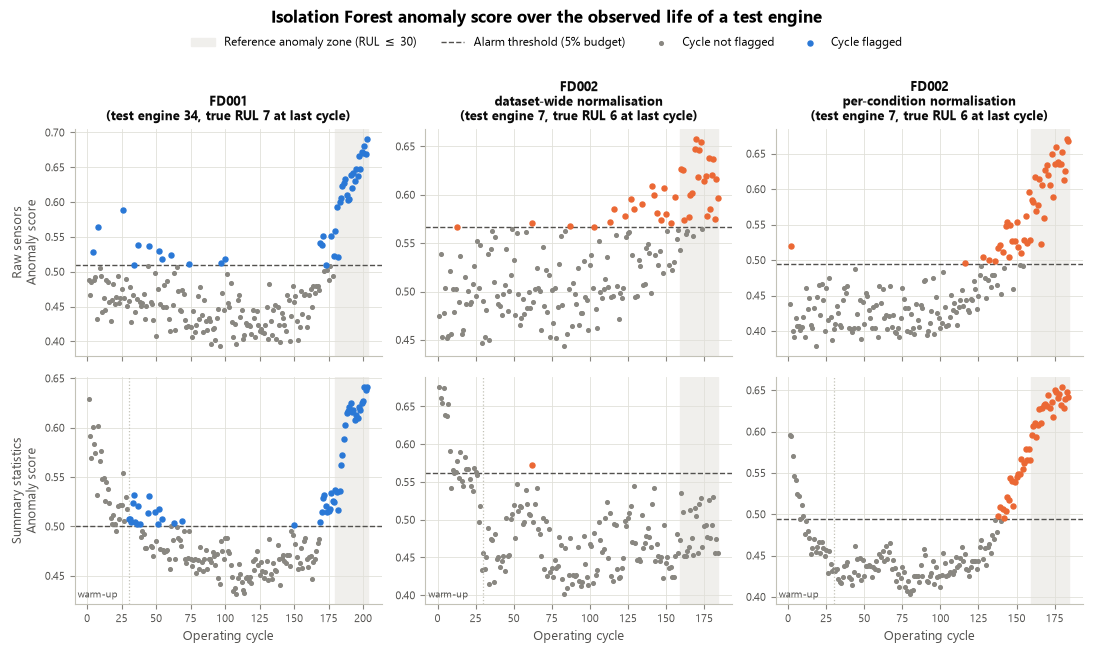

In [6]:
fig = ev.plot_anomaly_trajectories()
plt.show()

**Reading the figure.** Each panel shows the test engine closest to failure at its last observed cycle. The score stays below the threshold for most of the engine's life and rises as failure approaches, crossing the threshold some time before the shaded reference zone begins. Under dataset-wide normalisation with summary statistics (bottom middle) the score does not rise at all.

## 5. Figure 6b - Share of cycles flagged as engines approach failure

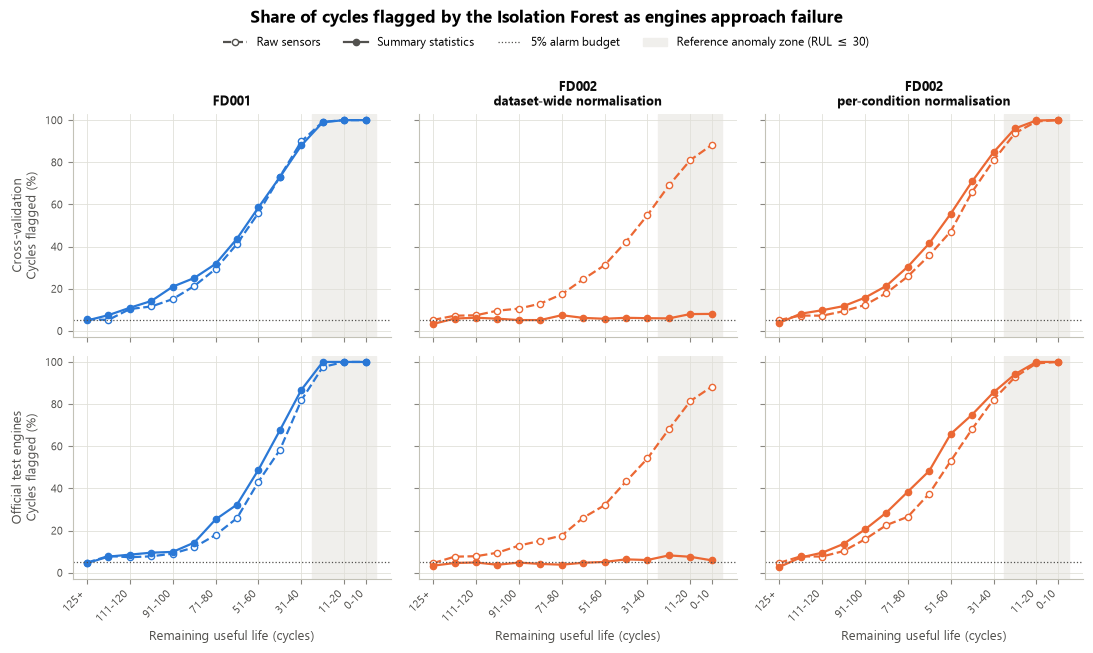

In [7]:
fig = ev.plot_alarm_rate_by_rul()
plt.show()

**Reading the figure.** The share of flagged cycles is close to the 5% budget for healthy engines and rises steadily as remaining life falls, reaching about 80 to 90% at 31 to 40 cycles and nearly 100% inside the reference zone. The detector responds to gradual degradation, so there is no sharp change at 30 cycles. This is why precision against a fixed 30-cycle label is low while recall is high.

## 6. Sensitivity to the alarm budget (test engines, all cycles)

In [8]:
full = ev.anomaly_results_table(main_only=False)
part = full[(full['evaluation'] == 'Test') & (full['scoring'] == 'all cycles')]
part.pivot_table(index=['data', 'representation'], columns='alarm_budget',
                 values=['precision', 'recall', 'f1'], sort=False).round(3)

precision                \
alarm_budget                                               0.01   0.05   0.10   
data                               representation                               
FD001                              Raw sensors            0.341  0.193  0.136   
                                   Summary statistics     0.295  0.181  0.139   
FD002, dataset-wide normalisation  Raw sensors            0.301  0.199  0.151   
                                   Summary statistics     0.049  0.063  0.060   
FD002, per-condition normalisation Raw sensors            0.318  0.196  0.146   
                                   Summary statistics     0.255  0.187  0.154   

                                                      recall                \
alarm_budget                                            0.01   0.05   0.10   
data                               representation                            
FD001                              Raw sensors         0.949  0.985  0.994   
                                   Summary statistics  0.982  1.000  1.000   
FD002, dataset-wide normalisation  Raw sensors         0.540  0.747  0.851   
                                   Summary statistics  0.011  0.078  0.152   
FD002, per-condition normalisation Raw sensors         0.915  0.959  0.972   
                                   Summary statistics  0.956  0.969  0.975   

                                                          f1                
alarm_budget                                            0.01   0.05   0.10  
data                               representation                           
FD001                              Raw sensors         0.502  0.323  0.240  
                                   Summary statistics  0.454  0.307  0.243  
FD002, dataset-wide normalisation  Raw sensors         0.386  0.315  0.256  
                                   Summary statistics  0.018  0.070  0.086  
FD002, per-condition normalisation Raw sensors         0.472  0.325  0.254  
                                   Summary statistics  0.402  0.313  0.266

**Reading the table.** A stricter budget (1%) raises precision and F1 and lowers recall slightly; a looser one (10%) does the opposite. The 5% budget was fixed in advance and is the reported result. The other two columns show how the trade-off moves and were not used to choose a setting.

## 7. Summary of evidence

1. **Detection (RQ1, diagnostic part).** Trained on healthy data only, the Isolation Forest flags 96 to 100% of near-failure cycles on FD001 and on FD002 with per-condition normalisation.
2. **Precision.** Against the 30-cycle reference label precision is about 0.19 on the test engines (F1 about 0.32), mainly because the detector also flags engines in earlier stages of degradation.
3. **Preprocessing matters for this model (RQ2).** On FD002, per-condition normalisation raises test recall from 0.75 to 0.96 with raw sensors, and from 0.08 to 0.97 with summary statistics.
4. **Feature representation (RQ2).** With suitable normalisation, raw sensors and summary statistics give similar results when all cycles are scored.

The reference label is a constructed proxy. These results show how well the detector separates late degradation from healthy operation in simulated data. They do not show that it detects real faults.